In [1]:
!pip install -q ultralytics

In [2]:
import os
import zipfile
import shutil
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO

random.seed(42)
np.random.seed(42)

DATASET_ZIP = "/content/kvasir-seg.zip"
DATASET_PATH = "/content/kvasir_dataset"
YOLO_PATH = "/content/kvasir_yolo"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
!wget --no-check-certificate -O /content/kvasir-seg.zip https://datasets.simula.no/downloads/kvasir-seg.zip

print("Arhive:", os.path.exists(DATASET_ZIP))

if os.path.exists(DATASET_ZIP):
    print(
        "Size:",
        round(os.path.getsize(DATASET_ZIP) / (1024 * 1024), 2),
        "MB"
    )

--2026-11-11 21:21:24--  https://datasets.simula.no/downloads/kvasir-seg.zip
Resolving datasets.simula.no (datasets.simula.no)... 128.39.36.14
Connecting to datasets.simula.no (datasets.simula.no)|128.39.36.14|:443... connected.
  Unable to locally verify the issuer's authority.
HTTP request sent, awaiting response... 200 OK
Length: 46227172 (44M) [application/zip]
Saving to: ‘/content/kvasir-seg.zip’

/content/kvasir-seg 100%[===================>]  44.08M  1.84MB/s    in 26s     

2026-11-11 21:21:50 (1.71 MB/s) - ‘/content/kvasir-seg.zip’ saved [46227172/46227172]

Arhive: True
Size: 44.09 MB


##Extraction of the data set

In [4]:
base_path = os.path.join(DATASET_PATH, "Kvasir-SEG")

if not os.path.exists(base_path):
    os.makedirs(DATASET_PATH, exist_ok=True)

    with zipfile.ZipFile(DATASET_ZIP, "r") as zip_ref:
        zip_ref.extractall(DATASET_PATH)

image_path = os.path.join(base_path, "images")
mask_path = os.path.join(base_path, "masks")

print("Images folder:", os.path.exists(image_path))
print("Masks folder:", os.path.exists(mask_path))

Images folder: True
Masks folder: True


##Verification of the images and masks


*   verify if every image has its own mask




In [5]:
image_files = sorted([
    f for f in os.listdir(image_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

mask_files = sorted([
    f for f in os.listdir(mask_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_map = {
    os.path.splitext(f)[0]: f
    for f in image_files
}

mask_map = {
    os.path.splitext(f)[0]: f
    for f in mask_files
}

paired_files = sorted(
    set(image_map.keys()) & set(mask_map.keys())
)

print("Number of images:", len(image_files))
print("Number of masks:", len(mask_files))
print("Valid image-mask pairs:", len(paired_files))

print("Images without masks:", len(set(image_map) - set(mask_map)))
print("Masks without images:", len(set(mask_map) - set(image_map)))

assert len(paired_files) > 0, "No valid image-mask pairs found!"

Number of images: 1000
Number of masks: 1000
Valid image-mask pairs: 1000
Images without masks: 0
Masks without images: 0


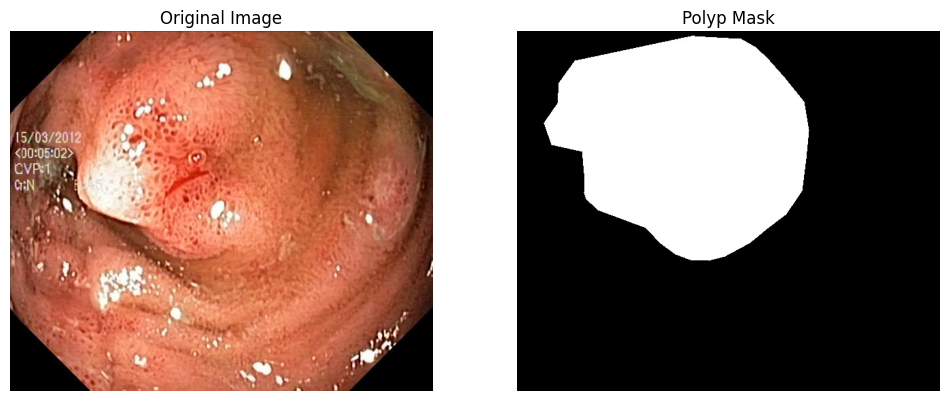

In [6]:
filename = paired_files[0]

image_file = os.path.join(
    image_path,
    image_map[filename]
)

mask_file = os.path.join(
    mask_path,
    mask_map[filename]
)

image = cv2.imread(image_file)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(
    mask_file,
    cv2.IMREAD_GRAYSCALE
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Polyp Mask")
plt.axis("off")

plt.show()

##Mask to Bounding box


*   Conversion from a mask to a binary image
*   Identifying the contour and computing the box that contains is



In [7]:
def mask_to_yolo(mask_file):

    mask = cv2.imread(
        mask_file,
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        raise ValueError(f"Mask can not be read: {mask_file}")

    height, width = mask.shape

    _, binary = cv2.threshold(
        mask,
        127,
        255,
        cv2.THRESH_BINARY
    )

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    labels = []

    for contour in contours:

        x, y, w, h = cv2.boundingRect(contour)

        if w == 0 or h == 0:
            continue

        x_center = (x + w / 2) / width
        y_center = (y + h / 2) / height

        box_width = w / width
        box_height = h / height

        labels.append(
            f"0 {x_center:.6f} {y_center:.6f} "
            f"{box_width:.6f} {box_height:.6f}"
        )

    return labels

In [8]:
test_mask = os.path.join(
    mask_path,
    mask_map[paired_files[0]]
)

test_labels = mask_to_yolo(test_mask)

print("Bounding boxes generate:")

for label in test_labels:
    print(label)

Bounding boxes generate:
0 0.377010 0.325142 0.628617 0.627599


##YOLO structure

In [9]:
if os.path.exists(YOLO_PATH):
    shutil.rmtree(YOLO_PATH)

folders = [
    "images/train",
    "images/val",
    "images/test",
    "labels/train",
    "labels/val",
    "labels/test"
]

for folder in folders:
    os.makedirs(
        os.path.join(YOLO_PATH, folder),
        exist_ok=True
    )

##Data Splitting

In [10]:
random.shuffle(paired_files)

total = len(paired_files)

train_end = int(0.70 * total)
val_end = int(0.85 * total)

train_files = paired_files[:train_end]
val_files = paired_files[train_end:val_end]
test_files = paired_files[val_end:]

print("Total:", total)
print("Train:", len(train_files))
print("Validation:", len(val_files))
print("Test:", len(test_files))

Total: 1000
Train: 700
Validation: 150
Test: 150


In [11]:
def prepare_dataset(files, split):

    for filename in files:

        image_file = os.path.join(
            image_path,
            image_map[filename]
        )

        mask_file = os.path.join(
            mask_path,
            mask_map[filename]
        )

        destination_image = os.path.join(
            YOLO_PATH,
            "images",
            split,
            image_map[filename]
        )

        label_filename = filename + ".txt"

        destination_label = os.path.join(
            YOLO_PATH,
            "labels",
            split,
            label_filename
        )

        shutil.copy2(
            image_file,
            destination_image
        )

        labels = mask_to_yolo(mask_file)

        with open(destination_label, "w") as f:
            f.write("\n".join(labels))


prepare_dataset(train_files, "train")
prepare_dataset(val_files, "val")
prepare_dataset(test_files, "test")

##Verification for dataset

In [12]:
for split in ["train", "val", "test"]:

    images_count = len(os.listdir(
        os.path.join(YOLO_PATH, "images", split)
    ))

    labels_count = len(os.listdir(
        os.path.join(YOLO_PATH, "labels", split)
    ))

    print(f"\n{split.upper()}")
    print("Number of images:", images_count)
    print("Number of labels:", labels_count)

    assert images_count == labels_count, (
        f"Image and label counts do not match in {split}"
    )


TRAIN
Number of images: 700
Number of labels: 700

VAL
Number of images: 150
Number of labels: 150

TEST
Number of images: 150
Number of labels: 150


In [13]:
yaml_content = """
path: /content/kvasir_yolo

train: images/train
val: images/val
test: images/test

nc: 1

names:
  0: polyp
"""

with open(
    os.path.join(YOLO_PATH, "data.yaml"),
    "w"
) as f:
    f.write(yaml_content)

##Loading the model YOLO11n

In [14]:
model = YOLO("yolo11n.pt")

##Model training


In [15]:
train_results = model.train(
    data="/content/kvasir_yolo/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    name="kvasir_yolo11n",
    seed=42,
    patience=20,
    plots=True,
    project="/content/runs/detect",
    exist_ok=True
)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kvasir_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=kvasir_yolo11n, nbs=64, nms=None, opset=None, optimize=Fal

##Best model

In [16]:
best_model = os.path.join(
    model.trainer.save_dir,
    "weights",
    "best.pt"
)

print("Best model exists:", os.path.exists(best_model))

assert os.path.exists(best_model), "best.pt was not found!"

best_model_yolo = YOLO(best_model)

Best model exists: True


##Evaluation on the validation set

In [17]:
val_metrics = best_model_yolo.val(
    data="/content/kvasir_yolo/data.yaml",
    split="val"
)

print("Validation Results")

print("Precision:", val_metrics.box.mp)
print("Recall:", val_metrics.box.mr)
print("mAP50:", val_metrics.box.map50)
print("mAP50-95:", val_metrics.box.map)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1339.0±367.1 MB/s, size: 36.2 KB)
val: Scanning /content/kvasir_yolo/labels/val.cache... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 44.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.7it/s 2.7s
                   all        150        185      0.904      0.773      0.814      0.646
Speed: 1.7ms preprocess, 4.6ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs/detect/val
Validation Results
Precision: 0.9043062207097378
Recall: 0.772972972972973
mAP50: 0.8136682010168578
mAP50-95: 0.6464404274374955


##Evaluation on the test dataset

In [18]:
test_metrics = best_model_yolo.val(
    data="/content/kvasir_yolo/data.yaml",
    split="test"
)

print("Test Results")

print("Precision:", test_metrics.box.mp)
print("Recall:", test_metrics.box.mr)
print("mAP50:", test_metrics.box.map50)
print("mAP50-95:", test_metrics.box.map)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1702.6±1179.7 MB/s, size: 60.4 KB)
val: Scanning /content/kvasir_yolo/labels/test... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 2.1Kit/s 0.1s
val: New cache created: /content/kvasir_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.2it/s 2.4s
                   all        150        173      0.907      0.798      0.848        0.7
Speed: 1.4ms preprocess, 4.5ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val-2
Test Results
Precision: 0.9067829749696157
Recall: 0.7976878612716763
mAP50: 0.848492379178325
mAP50-95: 0.6996188452770776



image 1/1 /content/kvasir_yolo/images/test/cju0s690hkp960855tjuaqvv0.jpg: 576x640 1 polyp, 7.8ms
Speed: 2.8ms preprocess, 7.8ms inference, 1.5ms postprocess per image at shape (1, 3, 576, 640)
Results saved to /content/runs/detect/predict


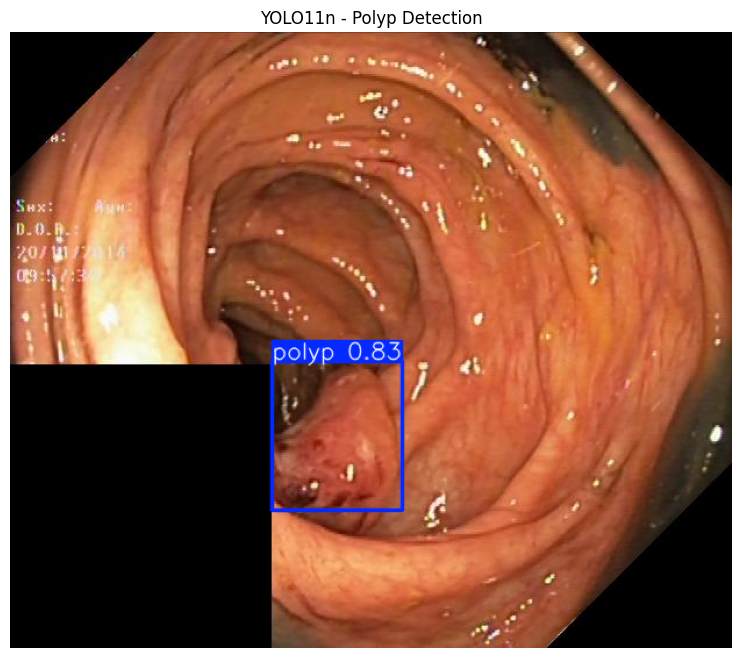

In [19]:
test_image_files = sorted(os.listdir(
    os.path.join(YOLO_PATH, "images", "test")
))

test_image = os.path.join(
    YOLO_PATH,
    "images",
    "test",
    test_image_files[0]
)

prediction = best_model_yolo.predict(
    source=test_image,
    conf=0.25,
    save=True
)

plt.figure(figsize=(10, 8))

plt.imshow(
    prediction[0].plot()[:, :, ::-1]
)

plt.title("YOLO11n - Polyp Detection")
plt.axis("off")

plt.show()

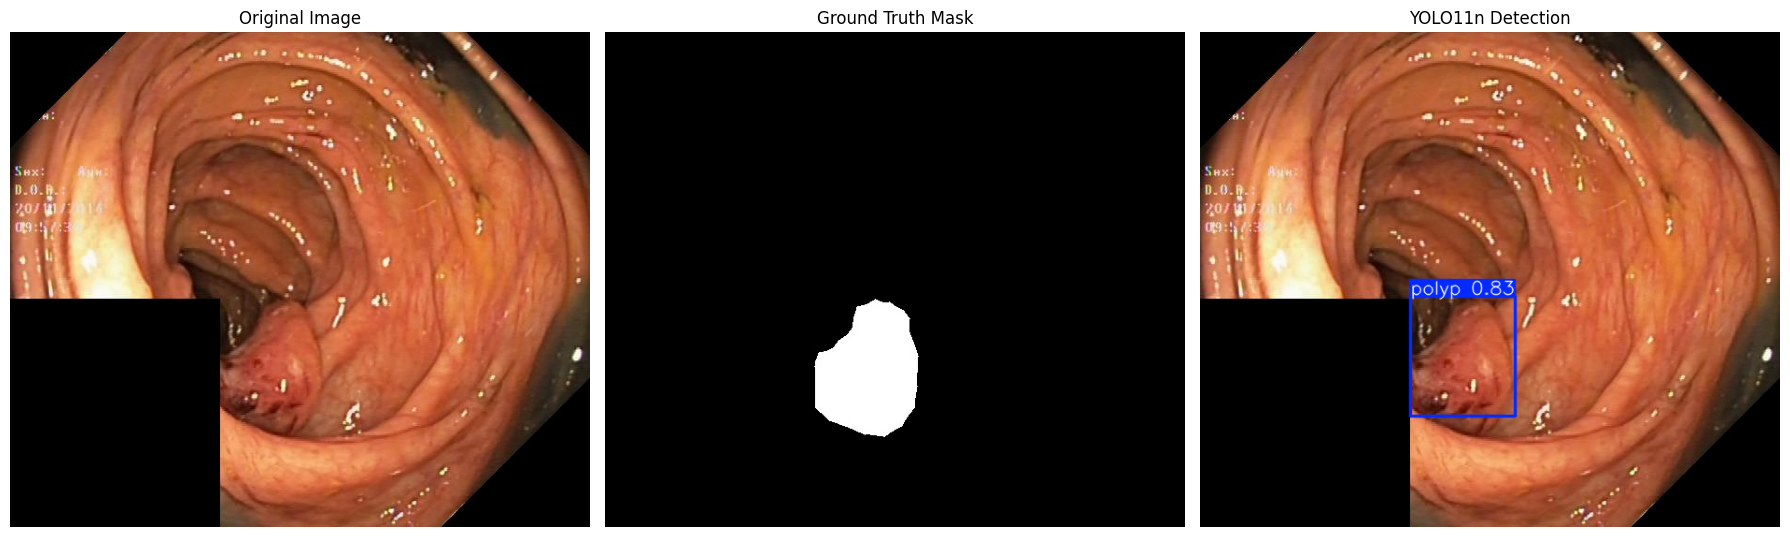

In [20]:
test_filename = os.path.splitext(
    test_image_files[0]
)[0]

original_image_file = os.path.join(
    image_path,
    image_map[test_filename]
)

original_mask_file = os.path.join(
    mask_path,
    mask_map[test_filename]
)

original_image = cv2.imread(original_image_file)
original_image = cv2.cvtColor(
    original_image,
    cv2.COLOR_BGR2RGB
)

original_mask = cv2.imread(
    original_mask_file,
    cv2.IMREAD_GRAYSCALE
)

detected_image = prediction[0].plot()
detected_image = cv2.cvtColor(
    detected_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(original_mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(detected_image)
plt.title("YOLO11n Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
shutil.copy2(
    best_model,
    "/content/best_yolo11n_kvasir.pt"
)

'/content/best_yolo11n_kvasir.pt'